# Think Bayes — Chapter 15: Two Dimensions (Joint Inference on μ, σ)
> *Reference: Paraphrased from Allen Downey's Think Bayes (2nd Edition, Chapter 15 "Two Dimensions").*

In this notebook, we extend the grid approximation to two continuous parameters simultaneously using `GridDistribution2d`.
We estimate the joint posterior distribution of the Mean $\mu$ and Standard Deviation $\sigma$ of a normally distributed sample (adult heights).

In [1]:
import set_paths
import numpy as np
import matplotlib.pyplot as plt
from probability.distributions import GridDistribution2d
from make_data import make_height_sample_data

## 15.1 Joint Normal Parameter Estimation
Suppose we have measured adult heights (in cm) for a sample of $N = 50$ individuals drawn from an unknown normal population $\mathcal{N}(\mu, \sigma^2)$.

In [2]:
heights = make_height_sample_data(n=50, seed=42)
print(f"Sample Size:        {len(heights)}")
print(f"Sample Mean:        {np.mean(heights):.3f} cm")
print(f"Sample Std (ddof=1):{np.std(heights, ddof=1):.3f} cm")

Sample Size:        50
Sample Mean:        173.309 cm
Sample Std (ddof=1):7.003 cm


## 15.2 2D Joint Prior and Bayesian Updating
We set up a 2D uniform prior over $\mu \in [165, 185]$ and $\sigma \in [4, 14]$ using `GridDistribution2d.uniform(...)`,
then update with the sample observations via `.update_normal(heights)`.

In [3]:
prior_2d = GridDistribution2d.uniform(
    x_low=165.0, x_high=185.0, x_num=100,
    y_low=4.0, y_high=14.0, y_num=100,
    x_name='μ (mean height)', y_name='σ (std dev)'
)

post_2d = prior_2d.update_normal(heights)

mode_mu, mode_sigma = post_2d.mode()
mean_mu, mean_sigma = post_2d.mean()
corr = post_2d.corr()

print(f"Joint MAP Mode:  μ = {mode_mu:.3f}, σ = {mode_sigma:.3f}")
print(f"Joint Mean:      μ = {mean_mu:.3f}, σ = {mean_sigma:.3f}")
print(f"Correlation:     r(μ, σ) = {corr:.4f}")

Joint MAP Mode:  μ = 173.283, σ = 6.929
Joint Mean:      μ = 173.309, σ = 7.188
Correlation:     r(μ, σ) = 0.0000


## 15.3 Marginal Distributions & Slicing Conditionals
From the joint 2D posterior $P(\mu, \sigma \mid D)$, we can integrate out one variable to find the marginal distribution,
or slice across a fixed value to find the conditional distribution.

In [4]:
# Marginals
marg_mu = post_2d.marginal_x()
marg_sigma = post_2d.marginal_y()

print(f"Marginal μ:     Mean = {marg_mu.mean():.3f}, 95% HDI = {marg_mu.hdi(0.95)}")
print(f"Marginal σ:     Mean = {marg_sigma.mean():.3f}, 95% HDI = {marg_sigma.hdi(0.95)}")

# Slicing conditional P(μ | σ = 7.5)
cond_mu = post_2d.conditional_x(given_y=7.5)
print(f"Conditional μ | σ≈7.5: Mean = {cond_mu.mean():.3f}, Std = {cond_mu.std():.3f}")

Marginal μ:     Mean = 173.309, 95% HDI = (171.46464646464648, 175.3030303030303)
Marginal σ:     Mean = 7.188, 95% HDI = (5.818181818181818, 8.646464646464647)
Conditional μ | σ≈7.5: Mean = 173.309, Std = 1.066


## 15.4 Visualizing the Joint Posterior: 2D Contours with 95% HDR
We plot the 2D joint density with an overlaid **95% Highest Density Region (HDR)** boundary curve.

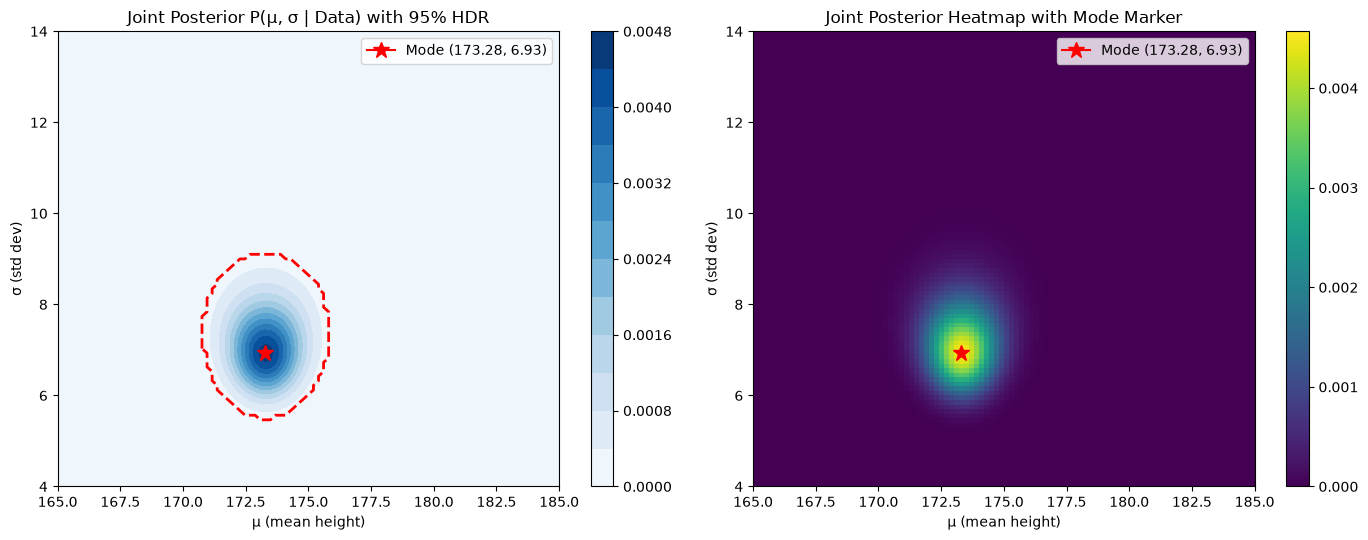

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# 1. Contour plot with 95% HDR
post_2d.plot_contour(
    ax=axes[0],
    levels=12,
    fill=True,
    cmap='Blues',
    hdr=0.95,
    title='Joint Posterior P(μ, σ | Data) with 95% HDR'
)

# 2. Heatmap
post_2d.plot_heatmap(
    ax=axes[1],
    cmap='viridis',
    title='Joint Posterior Heatmap with Mode Marker'
)

plt.tight_layout()
plt.show()